# Plot a figure for ORNL DAAC documentation

Map raster with ggplot

Paul Montesano, PhD

In [1]:
library(aws.s3)

In [2]:
library(terra)
library(tidyverse)
library(fs)
library(hexbin)

terra 1.7.78

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::extract() masks terra::extract()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
library(ggspatial)  # For adding a geographic grid (optional)
library(sf)

Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE



In [4]:
library(viridis)
library(patchwork)
library(reshape2)

Loading required package: viridisLite


Attaching package: ‘patchwork’


The following object is masked from ‘package:terra’:

    area



Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths




#### Figure export function

In [5]:
EXPORT_RDS_PNG_PDF <- function(m_plot_figure, OUT_FIGURE_DIR, DATA_NAME_STEM, VAR, EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(8,16), TYPE='map'){
    
    for(OUT_TYPE in c('rds','png', 'pdf')){
        
        map_fn = path(OUT_FIGURE_DIR, paste0(TYPE,"_",DATA_NAME_STEM,"_", VAR, EXPORT_TIME_STR,".", OUT_TYPE))
        print(map_fn)
        if(OUT_TYPE == 'rds'){
            saveRDS(m_plot_figure, map_fn)
        }else{
            ggsave(plot = m_plot_figure,
                   file = map_fn,
                   device = OUT_TYPE, dpi = 300, width=FIG_DIMS[1], height=FIG_DIMS[2])
            }
    }
}

In [6]:
theme_custom = list(
      theme_minimal() +
      theme(
          legend.position="top",
          legend.key.width=unit(2, "cm"),
          legend.key.height=unit(0.5, "cm"),
          legend.text=element_text(size=rel(1)),
        legend.title=element_text(size=rel(1.5))

      ),
          annotation_scale(location = "bl", style="ticks") ,
          #annotation_scale(location = "bl", style="box") ,
          annotation_north_arrow(location = "tl", which_north = "true", style=north_arrow_minimal())
    )
guides_ht = list(
            guides(
                    fill=guide_colourbar(
                             #limits = c(0, 25), breaks=c(0,5,10,15,20,25),
                            #title=expression(atop(H30[HLS+Topo]~"2020","Vegetation height [m]")), 
                             title=paste0("2020 ","Vegetation height [m]"),
                            title.position = "top", label.position = "bottom", 
                            #keywidth = unit(.05, "cm"), keyheight = unit(.25, "cm"), nrow=1
                             )
          )
    )
guides_agb_mean= list(
            guides(
                    fill=guide_colourbar(
                             #limits = c(0, 125), breaks=c(0,25,50,57,100,125),
                             #title=paste0("2020 ","Aboveground Woody Biomass Density [Mg/ha]") ,
                            title=expression("Mean aboveground woody biomass density ["~Mg~ha^{-1}~"]"),
                            #title=expression(atop(H30[HLS+Topo]~"2020","Aboveground Woody Biomass Density [Mg/ha]")), 
                            title.position = "top", label.position = "bottom", 
                            keywidth = unit(8, "cm"), keyheight = unit(.25, "cm"), nrow=1
                             )
         )
    )
guides_agb_stdv= list(
            guides(
                    fill=guide_colourbar(
                             #limits = c(0, 125), breaks=c(0,25,50,57,100,125),
                             #title=paste0("2020 ","Aboveground Woody Biomass Density [Mg/ha]") ,
                            title=expression("St. dev. aboveground woody biomass density ["~Mg~ha^{-1}~"]"),
                            #title=expression(atop(H30[HLS+Topo]~"2020","Aboveground Woody Biomass Density [Mg/ha]")), 
                            title.position = "top", label.position = "bottom", 
                            keywidth = unit(8, "cm"), keyheight = unit(.25, "cm"), nrow=1
                             )
         )
    )
guides_cacc= list(
            guides(
                    fill=guide_colourbar(

                            title=expression("Carbon accumulation ["~Mg~ha^{-1}~yr^{-1}~"]"),
                            title.position = "top", label.position = "bottom", 
                            keywidth = unit(8, "cm"), keyheight = unit(.25, "cm"), nrow=1
                             )
         )
    )

In [7]:
library(ggplot2)
library(dplyr)

# TTE Classification labels (matching the JavaScript/Python scripts)
tte_class_labels <- c(
  "1" = "Sparse & Abrupt",
  "2" = "Sparse & Diffuse-rapid",
  "3" = "Sparse & Diffuse-gradual", 
  "4" = "Sparse & Uniform",
  "5" = "Open & Uniform",
  "6" = "Open & Diffuse-gradual",
  "7" = "Open & Diffuse-rapid",
  "8" = "Open & Abrupt", 
  "9" = "Intermediate & Closed",
  "10" = "Non-forest edge (dry)",
  "11" = "Non-forest edge (wet)"
)

# TTE Classification colors (matching the original palette)
tte_colors <- c(
  "1" = "#5255a3",   # Sparse & Abrupt (dark blue)
  "2" = "#1796a3",   # Sparse & Diffuse-rapid (teal)
  "3" = "#fdbf6f",   # Sparse & Diffuse-gradual (light orange)
  "4" = "#ff7f00",   # Sparse & Uniform (orange)
  "5" = "#ffffbf",   # Open & Uniform (light yellow)
  "6" = "#d9ef8b",   # Open & Diffuse-gradual (light green)
  "7" = "#91cf60",   # Open & Diffuse-rapid (green)
  "8" = "#1a9850",   # Open & Abrupt (dark green)
  "9" = "#c4c4c4",   # Intermediate & Closed (gray)
  "10" = "#ff0000",  # Non-forest edge (dry) (red)
  "11" = "#0000ff"   # Non-forest edge (wet) (blue)
)

# TTE Classification guides for ggplot
guides_tte_classification <- list(
  guides(
    fill = guide_legend(
      title = "TTE Forest Structure Classification",
      title.position = "top",
      title.hjust = 0.5,
      label.position = "right",
      ncol = 3,  # Display in 3 columns
      nrow = 4,  # 4 rows to accommodate 11 classes
      byrow = TRUE,
      keywidth = unit(0.8, "cm"),
      keyheight = unit(0.6, "cm"),
      override.aes = list(
        shape = 22,  # Square shapes
        size = 3,
        stroke = 0.5,
        color = "black"  # Black border around legend keys
      )
    )
  )
)

# Alternative: Horizontal layout (single row)
guides_tte_horizontal <- list(
  guides(
    fill = guide_legend(
      title = "TTE Forest Structure Classification",
      title.position = "top", 
      title.hjust = 0.5,
      label.position = "bottom",
      ncol = 6,  # 6 columns
      nrow = 2,  # 2 rows 
      byrow = TRUE,
      keywidth = unit(1.2, "cm"),
      keyheight = unit(0.4, "cm"),
      label.theme = element_text(size = 8, angle = 0),
      override.aes = list(
        shape = 22,
        size = 2.5,
        stroke = 0.3
      )
    )
  )
)

# Alternative: Compact vertical layout
guides_tte_compact <- list(
  guides(
    fill = guide_legend(
      title = "TTE Classification",
      title.position = "top",
      title.hjust = 0.5,
      label.position = "right",
      ncol = 2,  # 2 columns
      nrow = 6,  # 6 rows
      byrow = FALSE,  # Fill by columns
      keywidth = unit(0.6, "cm"),
      keyheight = unit(0.5, "cm"),
      label.theme = element_text(size = 9),
      override.aes = list(
        shape = 22,
        size = 2.5,
        stroke = 0.4,
        color = "black"
      )
    )
  )
)

# Complete ggplot example
plot_tte_classification <- function(df, x_col, y_col, fill_col = "tte_class") {
  
  # Ensure the fill column is a factor with proper levels and labels
  df[[fill_col]] <- factor(df[[fill_col]], 
                          levels = names(tte_class_labels),
                          labels = tte_class_labels)
  
  p <- ggplot(df, aes_string(x = x_col, y = y_col, fill = fill_col)) +
    geom_raster() +  # or geom_tile() depending on your data
    scale_fill_manual(
      values = tte_colors,
      name = "TTE Classification",
      na.value = "transparent",
      drop = FALSE  # Show all levels even if not present in data
    ) +
    guides_tte_classification +  # Apply the guides
    coord_equal() +  # Equal aspect ratio
    theme_minimal() +
    theme(
      axis.title = element_text(size = 12),
      legend.title = element_text(size = 12, face = "bold"),
      legend.text = element_text(size = 10),
      panel.grid = element_blank(),
      axis.text = element_text(size = 10)
    ) +
    labs(
      x = "Longitude",
      y = "Latitude",
      title = "Taiga-Tundra Ecotone Forest Structure Classification"
    )
  
  return(p)
}

# Usage examples:

# Example 1: Basic plot with default 3-column legend
# ggplot(tte_df, aes(x = x, y = y, fill = factor(tte_class))) +
#   geom_raster() +
#   scale_fill_manual(values = tte_colors, labels = tte_class_labels) +
#   guides_tte_classification

# Example 2: With horizontal legend
# ggplot(tte_df, aes(x = x, y = y, fill = factor(tte_class))) +
#   geom_raster() +
#   scale_fill_manual(values = tte_colors, labels = tte_class_labels) +
#   guides_tte_horizontal

# Example 3: Using the complete function
# plot_tte_classification(tte_df, "x", "y", "tte_class")

# For discrete color scale (if using different aesthetics):
scale_fill_tte <- scale_fill_manual(
  values = tte_colors,
  labels = tte_class_labels,
  name = "TTE Classification",
  na.value = "transparent",
  drop = FALSE
)

scale_color_tte <- scale_color_manual(
  values = tte_colors,
  labels = tte_class_labels,
  name = "TTE Classification",
  na.value = "transparent",
  drop = FALSE
)

# Print the objects for easy access
cat("TTE Classification Components Created:\n")
cat("- tte_class_labels: Named vector with class labels\n")
cat("- tte_colors: Named vector with hex colors\n") 
cat("- guides_tte_classification: 3-column legend layout\n")
cat("- guides_tte_horizontal: 2-row horizontal layout\n")
cat("- guides_tte_compact: 2-column compact layout\n")
cat("- scale_fill_tte: Ready-to-use fill scale\n")
cat("- scale_color_tte: Ready-to-use color scale\n")
cat("- plot_tte_classification(): Complete plotting function\n")

TTE Classification Components Created:
- tte_class_labels: Named vector with class labels
- tte_colors: Named vector with hex colors
- guides_tte_classification: 3-column legend layout
- guides_tte_horizontal: 2-row horizontal layout
- guides_tte_compact: 2-column compact layout
- scale_fill_tte: Ready-to-use fill scale
- scale_color_tte: Ready-to-use color scale
- plot_tte_classification(): Complete plotting function


In [9]:
tte_tiles <- st_read('/projects/shared-buckets/montesano/databank/tte_tiles.gpkg')

Reading layer `tte_tiles' from data source 
  `/projects/shared-buckets/montesano/databank/tte_tiles.gpkg' 
  using driver `GPKG'
Simple feature collection with 4809 features and 4 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180.0004 ymin: 45.00014 xmax: 179.9998 ymax: 75.00014
Geodetic CRS:  WGS 84


In [9]:
Sys.setenv("AWS_DEFAULT_REGION" = "us-west-2") 

In [56]:
# Choose a TTE tile at FULL RESOLUTION
tindex_tte <- read.csv('/projects/shared-buckets/montesano/DPS_tile_lists/TTE/download_gee_tiles_v1//tte_montesano_2010_30m/TTE_tindex_master.csv')
TILE_NUM = 3250
tte_tile_select = tindex_tte %>% filter(tile_num == TILE_NUM)
raster_path = tte_tile_select$s3_path
RASTER_DF_NAMES = c('x','y','tte_domain','tte_zones','tte_abruptness','tte_classes','tcc')
raster_path

[1] "s3://maap-ops-workspace/montesano/dps_output/run_download_gee_tiles/download_gee_tiles_v1/tte_montesano_2010_30m/2025/11/15/06/04/15/388600/tte_montesano_2010_30m_0003250.tif"

In [37]:
# Choose a TTE mosiac at some COARSE RESOLUTION
raster_path = '/projects/my-public-bucket/DPS_tile_lists/TTE/download_gee_tiles_v1/tte_montesano_2010_30m/tte_classification_band4_6tiles_0p007500.tif'
RASTER_DF_NAMES = c('x','y','tte_classes')
raster_path

[1] "/projects/my-public-bucket/DPS_tile_lists/TTE/download_gee_tiles_v1/tte_montesano_2010_30m/tte_classification_band4_6tiles_0p007500.tif"

In [57]:
raster_read_proj_convert <- function(fn, DF_NAMES = c('x','y','value')){
    
    raster_proj <- rast(fn)    
    r <- project(raster_proj, "EPSG:4326")
    
    # # Check CRS and basic info
    # print(r)
    
    # Convert raster to data frame
    r_df <- as.data.frame(r, xy = TRUE)
    
    names(r_df) = DF_NAMES

    return (r_df)
    }

In [58]:
r_df = raster_read_proj_convert(raster_path, DF_NAMES = RASTER_DF_NAMES)

In [59]:
head(r_df)

,x,y,tte_domain,tte_zones,tte_abruptness,tte_classes,tcc,NA
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-164.0003,65.00088,NA,NA,NA,NA,NA,0
2,-164.0000,65.00088,NA,NA,NA,NA,NA,0
3,-163.9997,65.00088,NA,NA,NA,NA,NA,0
4,-163.9994,65.00088,NA,NA,NA,NA,NA,0
5,-163.9992,65.00088,NA,NA,NA,NA,NA,0
6,-163.9989,65.00088,NA,NA,NA,NA,NA,0


In [64]:
p_tte_classes = ggplot(r_df, aes(x = x, y = y, fill = factor(tte_classes))) +
    geom_raster() +  # or geom_tile() depending on your data
    scale_fill_tte +
    labs(x=NULL, y=NULL) +
    guides_tte_classification +  # Apply the guides
    coord_equal() +  # Equal aspect ratio
    theme_bw() +
    theme(
      axis.title = element_text(size = 12),
      legend.title = element_text(size = 10, face = "bold"),
      legend.text = element_text(size = 8),
      panel.grid = element_blank(),
      axis.text = element_text(size = 10)
    ) + theme_custom 


Using plotunit = 'm'

Warning message in draw_panel(...):
“True north is not meaningful without coord_sf()”


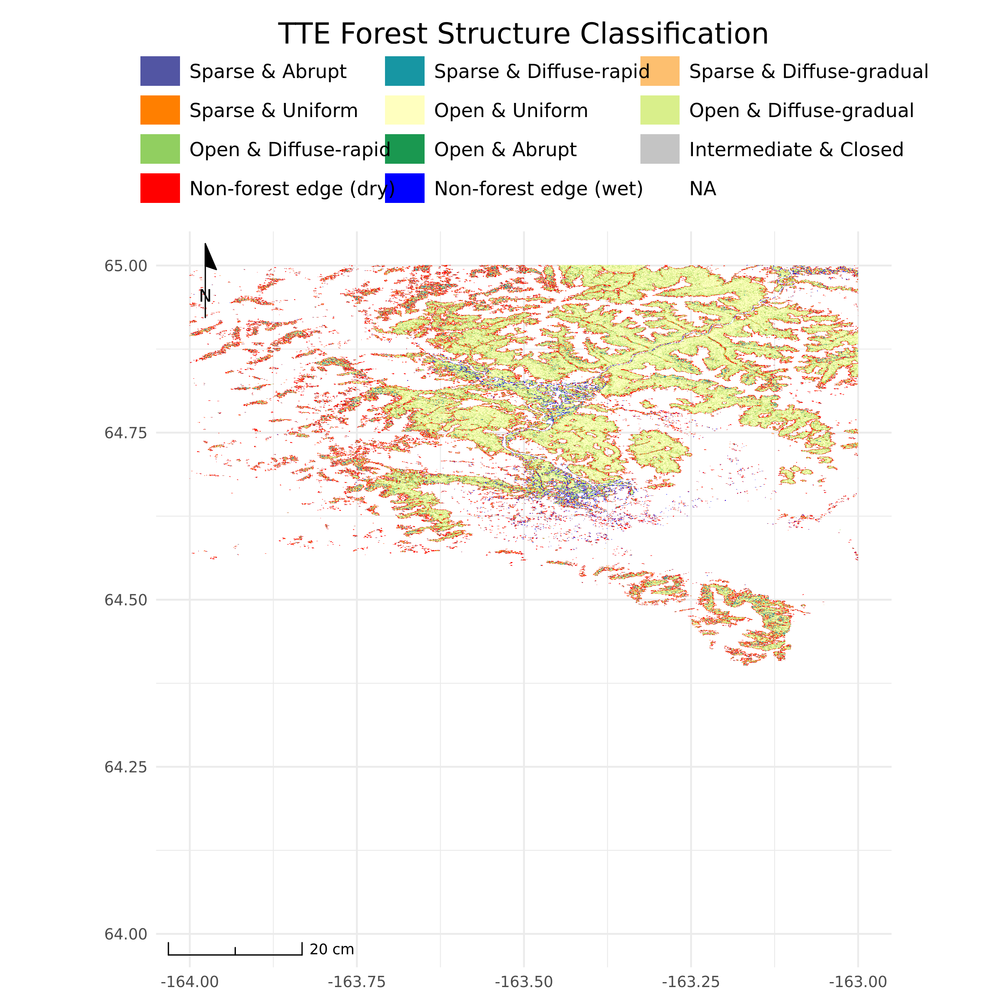

In [65]:
options(repr.plot.width = 8, repr.plot.height = 8, repr.plot.res = 300)

p_tte_classes + guides_tte_classification

Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”
Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”


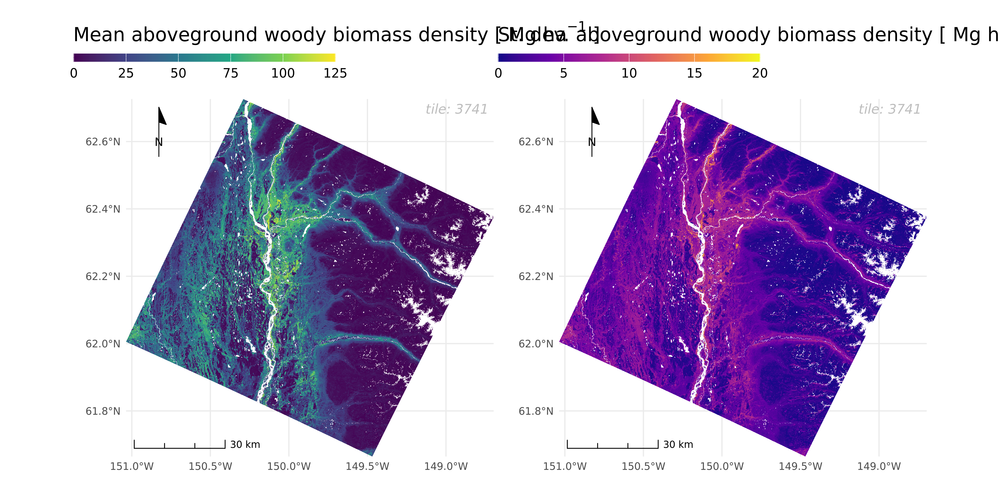

In [40]:
options(repr.plot.width = 12, repr.plot.height = 6, repr.plot.res = 300)

p_agb = (p_agb_mean | p_agb_std ) 
p_agb

## Export figure:
AGB mean and AGB std 

In [41]:
OUT_FIGURE_DIR = '/projects/my-public-bucket/boreal_AGB/paper_figs'

In [42]:
str_replace(basename(agb_tile_select$s3_path), '.tif','')

[1] "boreal_agb_2020_202510131760334188_0003741"

In [43]:
EXPORT_RDS_PNG_PDF(p_agb, OUT_FIGURE_DIR, 'boreal_agb_2020_', TILE_NUM, EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(12,6))

/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_agb_2020__3741_20251107.rds
/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_agb_2020__3741_20251107.png


Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”
Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”


/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_agb_2020__3741_20251107.pdf


Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”
Warning message:
“Raster pixels are placed at uneven horizontal intervals and will be shifted
ℹ Consider using `geom_tile()` instead.”


In [24]:
OUT_FIGURE_DIR = '/projects/my-public-bucket/boreal_AGB/paper_figs'
dir.create(OUT_FIGURE_DIR)

Warning message in dir.create(OUT_FIGURE_DIR):
“'/projects/my-public-bucket/boreal_AGB/paper_figs' already exists”


In [45]:
EXPORT_PNG_PDF(p_agb, OUT_FIGURE_DIR, paste0('tile_',TILE_NUM,'_AGBD'), 'MEAN_SD', EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(16,8), TYPE='map')

/projects/my-public-bucket/boreal_AGB/paper_figs/map_tile_3457_AGB_MEAN_SD_20250724.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_tile_3457_AGB_MEAN_SD_20250724.pdf


### For ORNL DAAC docs for `v3.0`

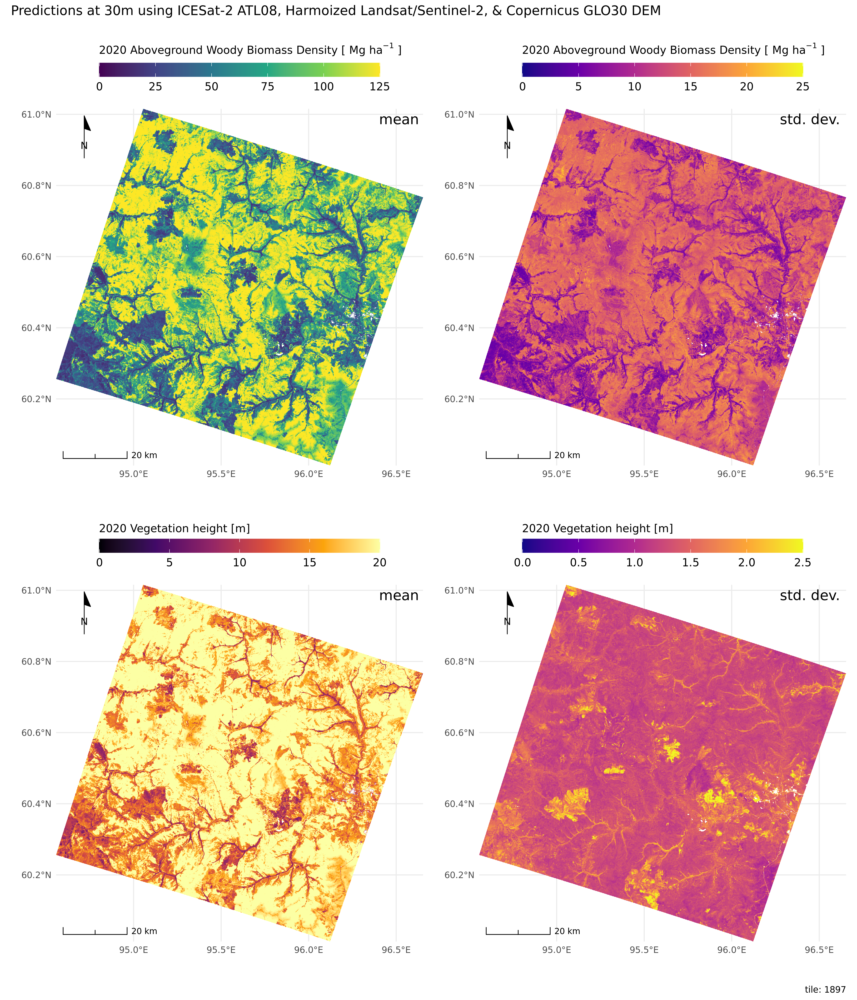

In [25]:
options(repr.plot.width = 12, repr.plot.height = 14, repr.plot.res = 300)

( (p_agb_mean + p_agb_std ) /  (p_ht_mean + p_ht_std) ) + plot_annotation(title = "Predictions at 30m using ICESat-2 ATL08, Harmoized Landsat/Sentinel-2, & Copernicus GLO30 DEM", caption=paste0("tile: ", TILE_NUM))

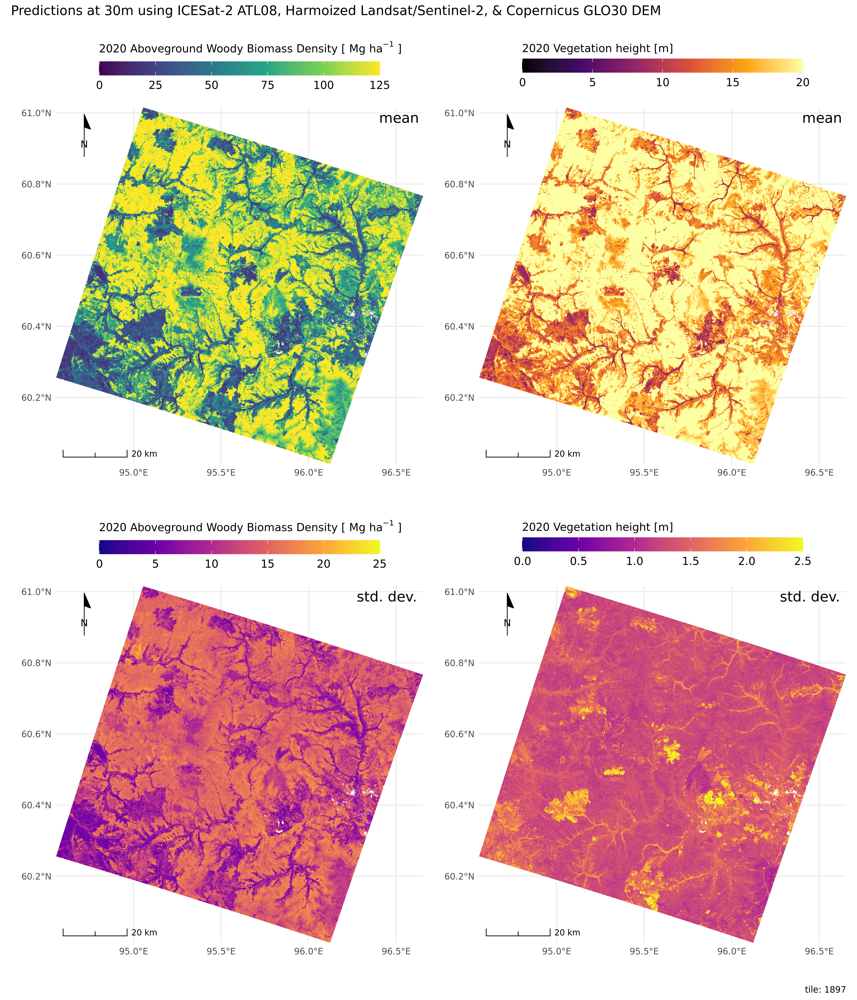

In [26]:
options(repr.plot.width = 12, repr.plot.height = 14, repr.plot.res = 300)

( (p_agb_mean + p_ht_mean) /  (p_agb_std + p_ht_std) ) + plot_annotation(title = "Predictions at 30m using ICESat-2 ATL08, Harmoized Landsat/Sentinel-2, & Copernicus GLO30 DEM", caption=paste0("tile: ", TILE_NUM))

---------------------------------------------



### OLD 
#### Map raster example

In [9]:
ht <- projectRaster(raster(tindex$s3_path[100]), crs=4326)

In [6]:
# Convert raster to "SpatialPixelsDataFrame" (can also use "SpatialGridDataFrame")
# https://gis.stackexchange.com/questions/363109/sf-spatialgriddataframe-vs-spatialpixelsdataframe-processing-visualization-an
ht_spdf <- as(ht, "SpatialPixelsDataFrame")

In [7]:
ht_sf = st_as_sf(ht_spdf)

In [8]:
colnames(ht_sf) = c('value', 'geometry')

In [9]:
dim(ht_sf)

[1] 9744413       2

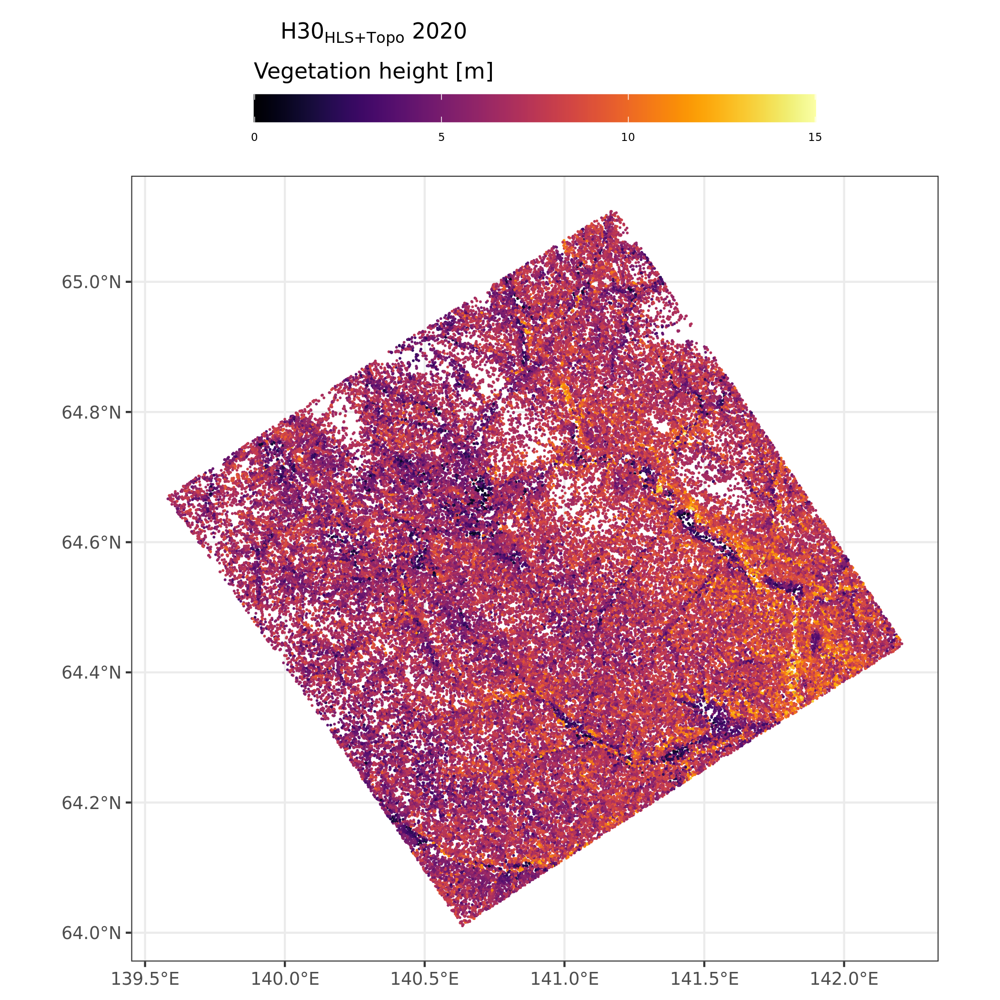

In [13]:
options(repr.plot.width = 7, repr.plot.height =7, repr.plot.res = 300)

ggplot() +  
    geom_sf(data=sample_frac(ht_sf,0.01) %>% st_transform(crs = 4326), aes(color=value), alpha=1, size=0.001) + 
    scale_color_viridis(option='inferno', limits=c(0,15)) +
    #coord_sf() +
    theme_custom

In [11]:
ht_df <- as.data.frame(ht_spdf)
colnames(ht_df) <- c("value", "x", "y")

In [18]:
# Read and crop: https://stackoverflow.com/questions/50827870/read-only-a-crop-or-extent-of-a-raster-in-r
#ht_df %>% filter((x>-104.5) & (x<-104) & (y>64.2) & (y<64.6))

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 7, repr.plot.res = 300)

ggplot() +  
    geom_tile(data=ht_df %>% filter((x>140.5) & (x<141.5) & (y>64.25) & (y<64.65)), aes(x=x, y=y, fill=value), alpha=1) + 
    scale_fill_viridis(option='inferno') +
    #coord_equal() +
    theme_custom

In [ ]:
ggplot(boreal_tiles %>% st_transform(crs=3995)) +
    geom_sf() +
    geom_tile(data=ht_df %>% filter((x>140.5) & (x<141.5) & (y>64.25) & (y<64.65)), aes(x=x, y=y, fill=value), alpha=1) + 
    scale_fill_viridis(option='inferno') +
    #coord_equal() +
    theme_custom +
theme_minimal()